# 01 · Exploratory data analysis

**Phase 2 deliverable.** This notebook describes the cleaned IPL match data (2008–2024): season coverage, class balance, team performance, toss effects, venue trends, and missing data. Everything here is a **historical observation over the whole dataset**, not a model result. It is used to shape features and set realistic expectations. Model features in Phase 3 will use only matches before each prediction date.

Inputs: `data/processed/matches_clean.csv`, produced by `python -m src.data.cleaning`. Charts are also saved to `reports/figures/`.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import viz
from src.data import mappings

viz.apply_style()
FIGURES = ROOT / "reports" / "figures"
pd.set_option("display.precision", 3)

manifest = json.loads((ROOT / "data/processed/manifest.json").read_text())
df = pd.read_csv(ROOT / manifest["output"]["file"], parse_dates=["date"])
assert len(df) == manifest["output"]["rows"], "cleaned file does not match manifest; rerun cleaning"

# Derived, descriptive-only columns. Batting order follows from the toss
# (verified against deliveries.csv in Phase 1).
other = np.where(df["toss_winner"] == df["team1"], df["team2"], df["team1"])
df["bat_first"] = np.where(df["toss_decision"] == "bat", df["toss_winner"], other)
df["chase_won"] = df["winner"] != df["bat_first"]
df["toss_winner_won"] = df["winner"] == df["toss_winner"]

print(f"{len(df):,} decided matches, {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}, "
      f"{df['season'].nunique()} seasons, {df['venue'].nunique()} grounds, "
      f"{pd.concat([df.team1, df.team2]).nunique()} franchises")

1,090 decided matches, 2008-04-18 to 2024-05-26, 17 seasons, 36 grounds, 15 franchises


## 1. Season coverage

Most seasons have 57–60 matches. The jump to 72–76 in 2011–2013 and from 2022 onward comes from 9- and 10-team leagues. Three seasons were played partly or wholly outside India: 2009 in South Africa, the opening phase of 2014 in the UAE, and 2020 plus the second half of 2021 in the UAE. Those conditions differ from typical Indian grounds, so venue history from those seasons is less transferable.

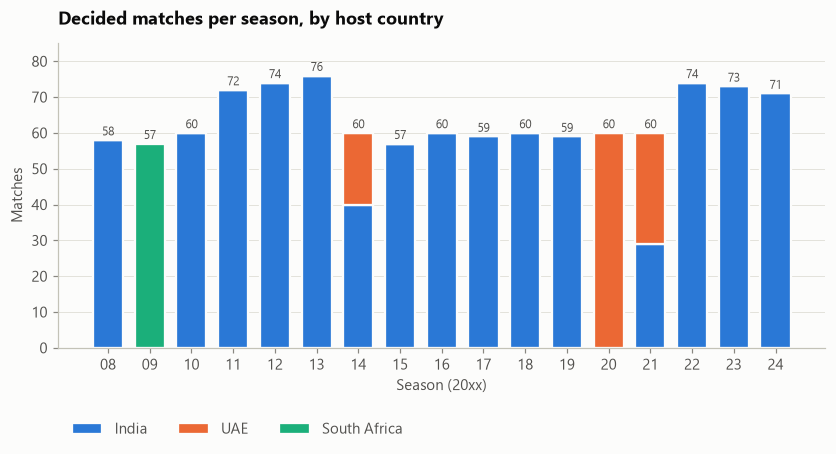

season,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
country,,,,,,,,,,,,,,,,,
India,58,0,60,72,74,76,40,57,60,59,60,59,0,29,74,73,71
UAE,0,0,0,0,0,0,20,0,0,0,0,0,60,31,0,0,0
South Africa,0,57,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
total,58,57,60,72,74,76,60,57,60,59,60,59,60,60,74,73,71
playoffs,3,3,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4


In [2]:
by_country = (df.groupby(["season", "country"]).size().unstack(fill_value=0)
              [["India", "UAE", "South Africa"]])

fig, ax = plt.subplots(figsize=(9, 3.6))
bottom = np.zeros(len(by_country))
for color, country in zip(viz.SERIES, by_country.columns):
    vals = by_country[country].to_numpy()
    ax.bar(by_country.index, vals, bottom=bottom, color=color, width=0.72,
           edgecolor=viz.SURFACE, linewidth=1.5, label=country)
    bottom += vals
for x, total in zip(by_country.index, bottom):
    ax.annotate(f"{int(total)}", (x, total), xytext=(0, 3), textcoords="offset points",
                ha="center", fontsize=8, color=viz.INK_SECONDARY)
ax.set_title("Decided matches per season, by host country", pad=12)
ax.set_ylim(0, bottom.max() * 1.12)
ax.set_xticks(by_country.index, [str(s)[2:] for s in by_country.index])
ax.set_xlabel("Season (20xx)")
ax.set_ylabel("Matches")
ax.grid(axis="x", visible=False)
ax.legend(ncols=3, loc="upper left", bbox_to_anchor=(0, -0.2))
viz.save(fig, "01_matches_per_season", FIGURES)
by_country.assign(total=by_country.sum(axis=1), playoffs=df.groupby("season")["is_playoff"].sum()).T

## 2. Class balance

The target is `team1_win`. Across all decided matches, `team1` wins about half the time. The share swings by season (from 38% to 71%) because the team1/team2 order in the source has no fixed meaning (Phase 1 finding). The classes are balanced overall, so accuracy is a meaningful metric. A model must not learn "team1 tends to win" as a rule, so Phase 3 should consider adding each match a second time with the teams swapped.

Overall team1 win share: 50.9% (555 of 1090)


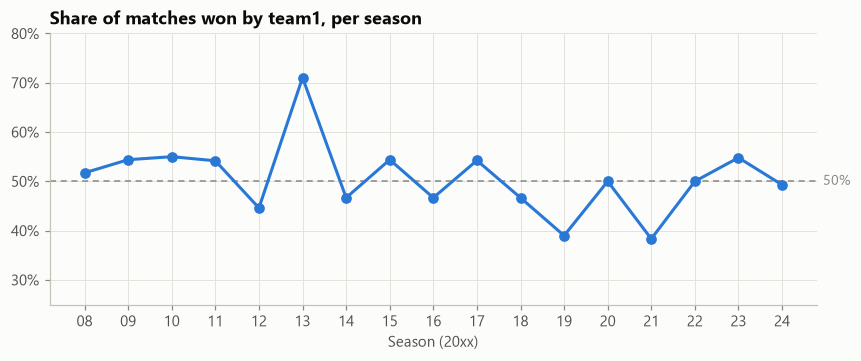

season,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
mean,0.517,0.544,0.55,0.542,0.446,0.711,0.467,0.544,0.467,0.542,0.467,0.39,0.5,0.383,0.5,0.548,0.493
size,58.000,57.000,60.00,72.000,74.000,76.000,60.000,57.000,60.000,59.000,60.000,59.00,60.0,60.000,74.0,73.000,71.000


In [3]:
balance = df.groupby("season")["team1_win"].agg(["mean", "size"])
print(f"Overall team1 win share: {df['team1_win'].mean():.1%} "
      f"({df['team1_win'].sum()} of {len(df)})")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(balance.index, balance["mean"], color=viz.BLUE, marker="o")
viz.reference_line(ax, 0.5)
ax.set_ylim(0.25, 0.8)
viz.percent_axis(ax)
ax.set_xticks(balance.index, [str(s)[2:] for s in balance.index])
ax.set_title("Share of matches won by team1, per season")
ax.set_xlabel("Season (20xx)")
viz.save(fig, "02_class_balance", FIGURES)
balance.T

## 3. Team performance

All-time win rates range from 27% (Pune Warriors) to 62% (Gujarat Titans). Long-running franchises sit closer to 50%; Chennai Super Kings (58%) and Mumbai Indians (55%) lead among them. Small samples make newer or defunct teams' rates noisy: Gujarat Titans have only 45 matches.

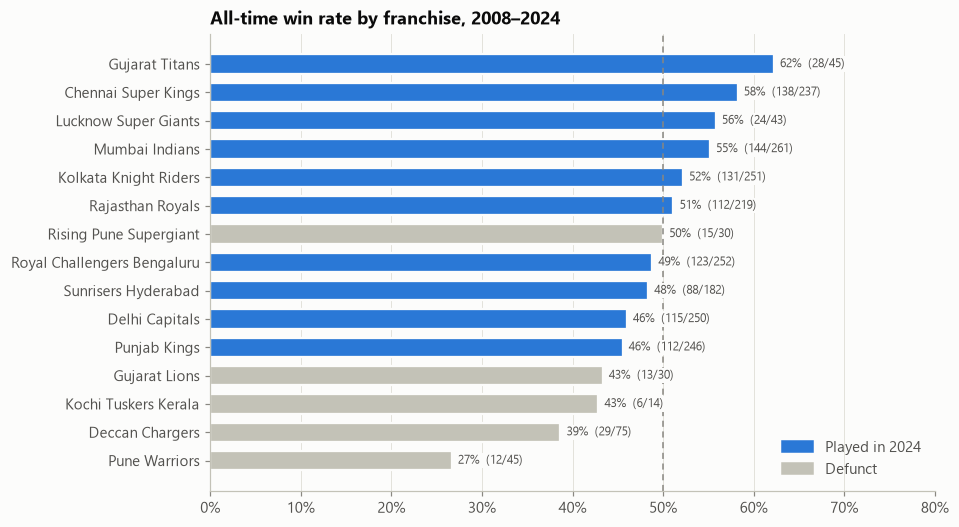

,played,wins,win_rate,active_2024
team,,,,
Gujarat Titans,45,28,0.622,True
Chennai Super Kings,237,138,0.582,True
Lucknow Super Giants,43,24,0.558,True
Mumbai Indians,261,144,0.552,True
Kolkata Knight Riders,251,131,0.522,True
Rajasthan Royals,219,112,0.511,True
Rising Pune Supergiant,30,15,0.500,False
Royal Challengers Bengaluru,252,123,0.488,True
Sunrisers Hyderabad,182,88,0.484,True


In [4]:
long = pd.concat([
    df[["season", "team1", "winner"]].rename(columns={"team1": "team"}),
    df[["season", "team2", "winner"]].rename(columns={"team2": "team"}),
])
long["won"] = long["team"] == long["winner"]
teams = (long.groupby("team")["won"].agg(played="size", wins="sum", win_rate="mean")
         .sort_values("win_rate"))
teams["active_2024"] = teams.index.isin(mappings.ACTIVE_TEAMS)

fig, ax = plt.subplots(figsize=(8.5, 5.4))
colors = np.where(teams["active_2024"], viz.BLUE, viz.NEUTRAL_MARK)
ax.barh(teams.index, teams["win_rate"], color=colors, height=0.68,
        edgecolor=viz.SURFACE, linewidth=1.5)
for y, (rate, w, p) in enumerate(teams[["win_rate", "wins", "played"]].to_numpy()):
    ax.annotate(f"{rate:.0%}  ({int(w)}/{int(p)})", (rate, y), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=8, color=viz.INK_SECONDARY,
                bbox=dict(boxstyle="square,pad=0.15", fc=viz.SURFACE, ec="none"))
viz.reference_line(ax, 0.5, axis="x", label=None)
viz.percent_axis(ax, "x")
ax.set_xlim(0, 0.8)
ax.grid(axis="y", visible=False)
ax.set_title("All-time win rate by franchise, 2008–2024")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=viz.BLUE, label="Played in 2024"),
                   Patch(color=viz.NEUTRAL_MARK, label="Defunct")],
          loc="lower right")
viz.save(fig, "03_team_win_rate", FIGURES)
teams.sort_values("win_rate", ascending=False)

### Team form changes a lot between seasons

The grid below shows each active franchise's win rate per season (blank = did not play). The same franchise can finish near the top one year and near the bottom the next. All-time win rates alone will be weak predictors; **recent form** and **season-to-date** features should carry more signal. That is the Phase 3 priority. Blank cells are seasons a team did not play; Chennai Super Kings and Rajasthan Royals were suspended in 2016–17.

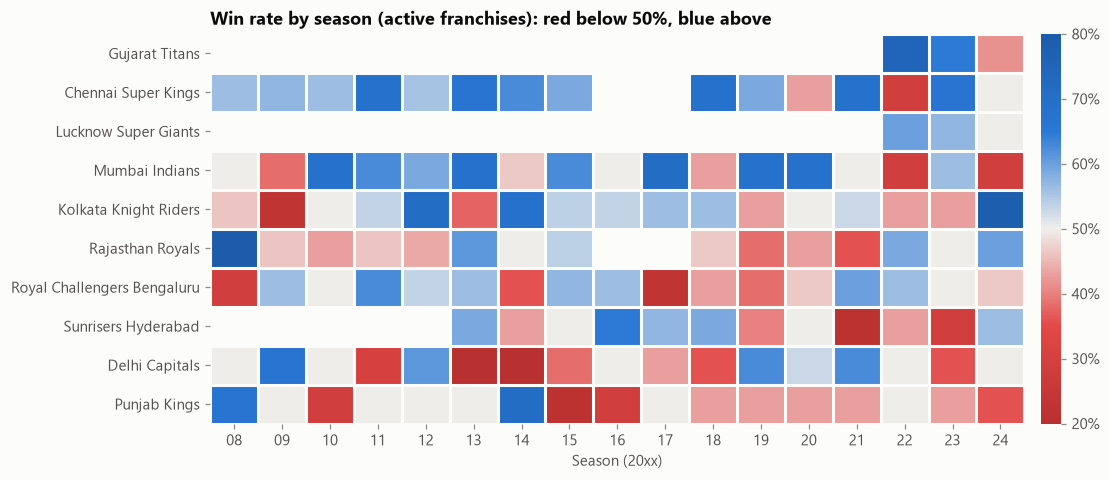

season,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
team,,,,,,,,,,,,,,,,,
Gujarat Titans,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.75,0.65,0.42
Chennai Super Kings,0.56,0.57,0.56,0.69,0.56,0.67,0.62,0.59,NaN,NaN,0.69,0.59,0.43,0.69,0.29,0.67,0.50
Lucknow Super Giants,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.60,0.57,0.50
Mumbai Indians,0.50,0.38,0.69,0.62,0.59,0.68,0.47,0.62,0.50,0.71,0.43,0.69,0.69,0.50,0.29,0.56,0.29
Kolkata Knight Riders,0.46,0.23,0.50,0.53,0.71,0.38,0.69,0.54,0.53,0.56,0.56,0.43,0.50,0.53,0.43,0.43,0.79
Rajasthan Royals,0.81,0.46,0.43,0.46,0.44,0.61,0.50,0.54,NaN,NaN,0.47,0.38,0.43,0.36,0.59,0.50,0.60
Royal Challengers Bengaluru,0.29,0.56,0.50,0.62,0.53,0.56,0.36,0.57,0.56,0.23,0.43,0.38,0.47,0.60,0.56,0.50,0.47
Sunrisers Hyderabad,NaN,NaN,NaN,NaN,NaN,0.59,0.43,0.50,0.65,0.57,0.59,0.40,0.50,0.21,0.43,0.29,0.56
Delhi Capitals,0.50,0.67,0.50,0.31,0.61,0.19,0.14,0.38,0.50,0.43,0.36,0.62,0.53,0.62,0.50,0.36,0.50


In [5]:
active = sorted(mappings.ACTIVE_TEAMS)
grid = (long[long["team"].isin(active)]
        .groupby(["team", "season"])["won"].mean().unstack())
grid = grid.loc[grid.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(10, 4.6))
im = ax.imshow(grid.to_numpy(dtype=float), cmap=viz.DIVERGING, vmin=0.2, vmax=0.8, aspect="auto")
ax.set_xticks(range(grid.shape[1]), [str(s)[2:] for s in grid.columns])
ax.set_yticks(range(grid.shape[0]), grid.index)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks(np.arange(-.5, grid.shape[1]), minor=True)
ax.set_yticks(np.arange(-.5, grid.shape[0]), minor=True)
ax.grid(which="minor", color=viz.SURFACE, linewidth=2)
ax.tick_params(which="minor", length=0)
ax.set_xlabel("Season (20xx)")
ax.set_title("Win rate by season (active franchises): red below 50%, blue above")
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, format=lambda v, _: f"{v:.0%}")
cbar.outline.set_visible(False)
cbar.ax.tick_params(colors=viz.INK_MUTED, labelcolor=viz.INK_SECONDARY)
viz.save(fig, "04_team_season_heatmap", FIGURES)
grid.round(2)

## 4. Toss effects

Winning the toss barely helps on its own. The toss winner wins **50.8%** of decided matches. That is the accuracy of the "toss winner wins" baseline, essentially a coin flip. The **decision** matters more: toss winners who chose to field won 53.9%, and those who chose to bat won 45.4%. Chasing teams won 54.1% of matches overall.

Captains noticed this. The share of tosses where the winner chose to field rose from under half (2009–2013) to about three-quarters (2016 onward). The toss decision should therefore be an input, and features should allow its effect to change over time.

Toss winner won: 50.8%   Chasing team won: 54.1%


,matches,toss_winner_win_rate
toss_decision,,
bat,390,0.454
field,700,0.539


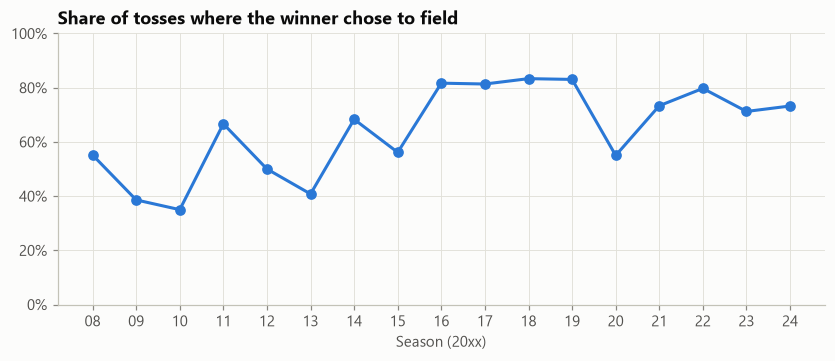

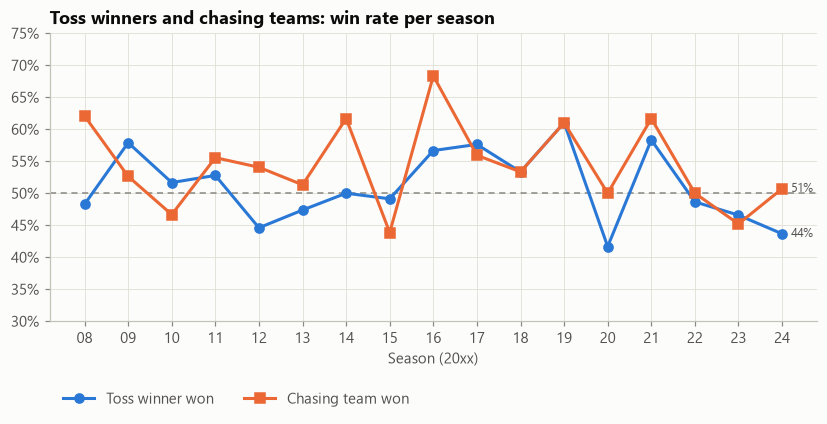

season,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
field_share,0.552,0.386,0.350,0.667,0.500,0.408,0.683,0.561,0.817,0.814,0.833,0.831,0.550,0.733,0.797,0.712,0.732
toss_winner_won,0.483,0.579,0.517,0.528,0.446,0.474,0.500,0.491,0.567,0.576,0.533,0.610,0.417,0.583,0.486,0.466,0.437
chase_won,0.621,0.526,0.467,0.556,0.541,0.513,0.617,0.439,0.683,0.559,0.533,0.610,0.500,0.617,0.500,0.452,0.507


In [6]:
by_decision = df.groupby("toss_decision")["toss_winner_won"].agg(matches="size", toss_winner_win_rate="mean")
print(f"Toss winner won: {df['toss_winner_won'].mean():.1%}   Chasing team won: {df['chase_won'].mean():.1%}")
display(by_decision)

toss = df.groupby("season").agg(
    field_share=("toss_decision", lambda s: (s == "field").mean()),
    toss_winner_won=("toss_winner_won", "mean"),
    chase_won=("chase_won", "mean"),
)
xt = [str(s)[2:] for s in toss.index]

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(toss.index, toss["field_share"], color=viz.BLUE, marker="o")
ax.set_ylim(0, 1)
viz.percent_axis(ax)
ax.set_xticks(toss.index, xt)
ax.set_xlabel("Season (20xx)")
ax.set_title("Share of tosses where the winner chose to field")
viz.save(fig, "05_field_choice_share", FIGURES)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(toss.index, toss["toss_winner_won"], color=viz.BLUE, marker="o", label="Toss winner won")
ax.plot(toss.index, toss["chase_won"], color=viz.ORANGE, marker="s", label="Chasing team won")
for col, color in (("toss_winner_won", viz.BLUE), ("chase_won", viz.ORANGE)):
    ax.annotate(f"{toss[col].iloc[-1]:.0%}", (toss.index[-1], toss[col].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8,
                color=viz.INK_SECONDARY)
viz.reference_line(ax, 0.5, label=None)
ax.set_ylim(0.3, 0.75)
viz.percent_axis(ax)
ax.set_xticks(toss.index, xt)
ax.set_xlabel("Season (20xx)")
ax.set_title("Toss winners and chasing teams: win rate per season")
ax.legend(ncols=2, loc="upper left", bbox_to_anchor=(0, -0.2))
viz.save(fig, "06_toss_and_chase_win_rate", FIGURES)
toss.T

## 5. Venue trends

Five grounds host 44% of all matches. Chasing advantage differs by ground: chasing teams won 65% at Sawai Mansingh (Jaipur) but only 42% at MA Chidambaram (Chennai), where batting first won more often. A venue-level "chasing win rate", combined with the toss decision, is a candidate Phase 3 feature. It must be computed only from earlier matches, and grounds with few matches need shrinking toward the overall rate.

Top 5 grounds host 476 of 1090 matches (44%).


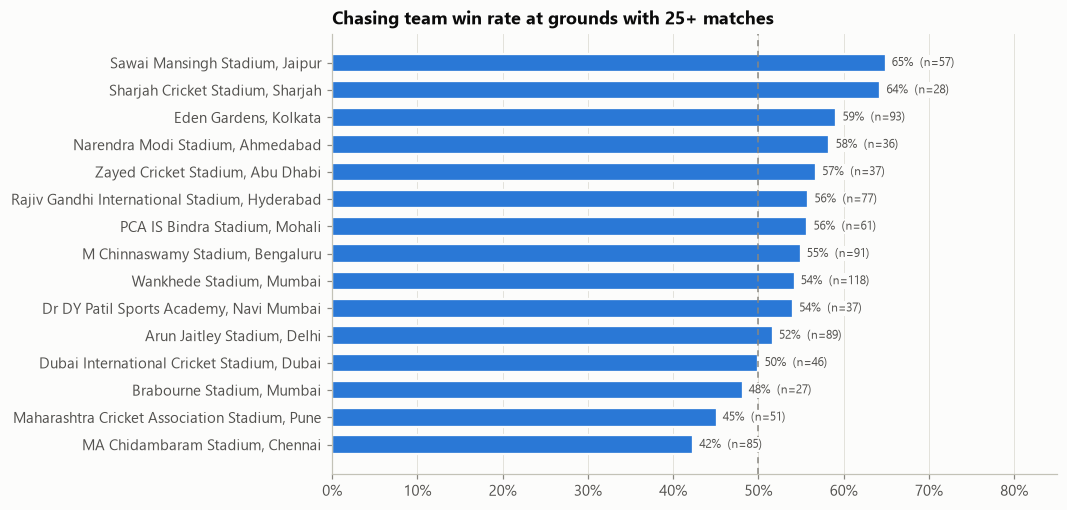

,matches,chase_win_rate,toss_winner_win_rate,country
venue,,,,
"Wankhede Stadium, Mumbai",118,0.542,0.525,India
"Eden Gardens, Kolkata",93,0.591,0.527,India
"M Chinnaswamy Stadium, Bengaluru",91,0.549,0.538,India
"Arun Jaitley Stadium, Delhi",89,0.517,0.506,India
"MA Chidambaram Stadium, Chennai",85,0.424,0.494,India
"Rajiv Gandhi International Stadium, Hyderabad",77,0.558,0.364,India
"PCA IS Bindra Stadium, Mohali",61,0.557,0.475,India
"Sawai Mansingh Stadium, Jaipur",57,0.649,0.526,India
"Maharashtra Cricket Association Stadium, Pune",51,0.451,0.549,India


In [7]:
venues = df.groupby("venue").agg(matches=("match_id", "size"), chase_win_rate=("chase_won", "mean"),
                                 toss_winner_win_rate=("toss_winner_won", "mean"),
                                 country=("country", "first"))
top5 = venues["matches"].nlargest(5).sum()
print(f"Top 5 grounds host {top5} of {len(df)} matches ({top5/len(df):.0%}).")

big = venues[venues["matches"] >= 25].sort_values("chase_win_rate")
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.barh(big.index, big["chase_win_rate"], color=viz.BLUE, height=0.68,
        edgecolor=viz.SURFACE, linewidth=1.5)
for y, (rate, n) in enumerate(big[["chase_win_rate", "matches"]].to_numpy()):
    ax.annotate(f"{rate:.0%}  (n={int(n)})", (rate, y), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8, color=viz.INK_SECONDARY,
                bbox=dict(boxstyle="square,pad=0.15", fc=viz.SURFACE, ec="none"))
viz.reference_line(ax, 0.5, axis="x", label=None)
viz.percent_axis(ax, "x")
ax.set_xlim(0, 0.85)
ax.grid(axis="y", visible=False)
ax.set_title("Chasing team win rate at grounds with 25+ matches")
viz.save(fig, "07_venue_chase_rate", FIGURES)
venues.sort_values("matches", ascending=False)

## 6. Missing data

Raw missing values come only from no-result matches, ties, and two UAE grounds with no city. After cleaning, the five no-result matches are dropped and city is derived from the venue. Every column that can be an input or the label is complete. The remaining gaps are in outcome-only columns that are never model inputs: `method` is empty unless D/L applied, and `result_margin` is empty for ties.

In [8]:
raw = pd.read_csv(ROOT / "data/raw/matches.csv", dtype=str, keep_default_na=False)
raw_missing = raw.apply(lambda s: s.str.strip().isin(["", "NA"]).sum())
rows = []
for col, n in raw_missing[raw_missing > 0].items():
    after = int(df[col].isna().sum()) if col in df.columns else "column dropped"
    rows.append((col, int(n), after))
missing = pd.DataFrame(rows, columns=["column", "missing_in_raw", "missing_after_cleaning"]).set_index("column")

model_cols = ["date", "season", "match_type", "is_playoff", "venue", "city", "country",
              "team1", "team2", "toss_winner", "toss_decision", "winner", "team1_win"]
print(f"Missing values in input and label columns after cleaning: {int(df[model_cols].isna().sum().sum())}")
missing

Missing values in input and label columns after cleaning: 0


,missing_in_raw,missing_after_cleaning
column,,
city,51,0
player_of_match,5,column dropped
winner,5,0
result_margin,19,14
target_runs,3,column dropped
target_overs,3,column dropped
method,1074,1069


## 7. Findings for later phases

| # | Finding | Consequence |
|---|---|---|
| 1 | Classes are balanced overall (team1 wins 50.9%), but the team1/team2 order is arbitrary and the share swings by season. | Accuracy is meaningful. Phase 3: train on each match twice with teams swapped, and check that predictions for (A, B) and (B, A) sum to 100%. |
| 2 | The toss winner wins 50.8% of the time. | The toss-winner baseline is about a coin flip. Any model must clearly beat ~51% on the held-out seasons to show value. |
| 3 | Choosing to field wins more (53.9% vs 45.4%), and field choice rose from under half to about three-quarters of tosses. | Include the toss decision. Expect drift: a time-based split is required, as agreed. |
| 4 | Win rates differ between franchises (27–62%) and swing strongly between seasons. | Prioritise recent-form and season-to-date features over all-time rates. |
| 5 | Chasing advantage varies by ground (42–65% at grounds with 25+ matches). | Venue chasing rate × toss decision is a candidate feature, smoothed toward the overall rate for small samples. |
| 6 | 2009 (South Africa), part of 2014, 2020, and part of 2021 (UAE) were played away from usual grounds. | Home-ground effects don't apply in those matches; `country` is available as context. |
| 7 | New franchises (Gujarat Titans, Lucknow Super Giants) have only 3 seasons each. | Historical features need sensible defaults (league average) when a team has little history. |

### Limitations

- Descriptive only. Rates over all seasons mix eras and include later matches, so they must not be used as features directly (leakage). Phase 3 recomputes them using only earlier matches.
- No player, squad, injury, pitch, or weather data. Much of what decides a T20 match is outside this dataset, so realistic accuracy is modest (roughly 55–60% in published work on similar inputs). The report should say this plainly.
- Small samples: 17 seasons, 1,090 matches, 57–76 per season. The later-season test set will have about 145 matches (2023–2024), so metric differences of a few points between models may not be meaningful.